Found 981 files belonging to 7 classes.
Classes: ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
Total samples: 981
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.4247 - loss: 1.6815 - val_accuracy: 0.6142 - val_loss: 1.0873
Epoch 2/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6429 - loss: 1.0295 - val_accuracy: 0.7056 - val_loss: 0.7972
Epoch 3/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7487 - loss: 0.7638 - val_accuracy: 0.7462 - val_loss: 0.6623
Epoch 4/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7628 - loss: 0.6613 - val_accuracy: 0.7766 - val_loss: 0.5807
Epoch 5/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7857 - loss: 0.5881 - val_accuracy: 0.7970 - val_loss: 0.4727
Epoch 6/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8163 - loss: 0.5028 - val_accuracy: 0.8579 - val_loss: 0.3691
Epoch 7/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - a

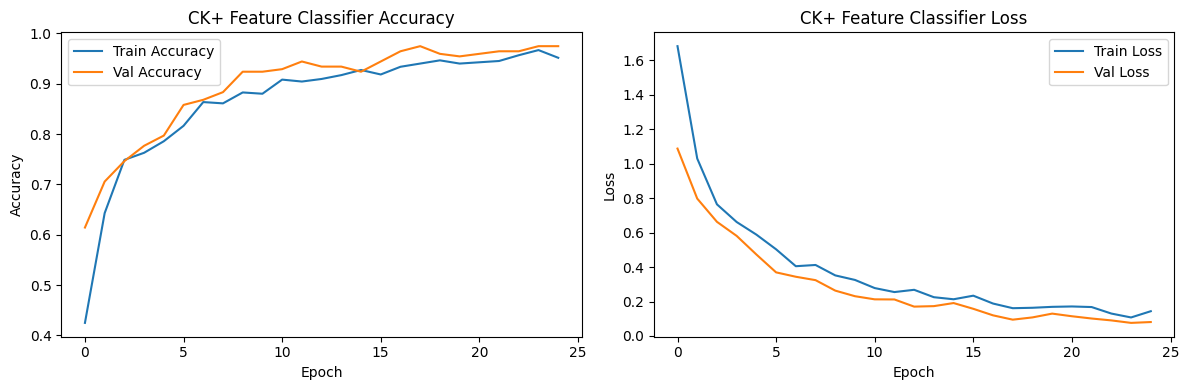

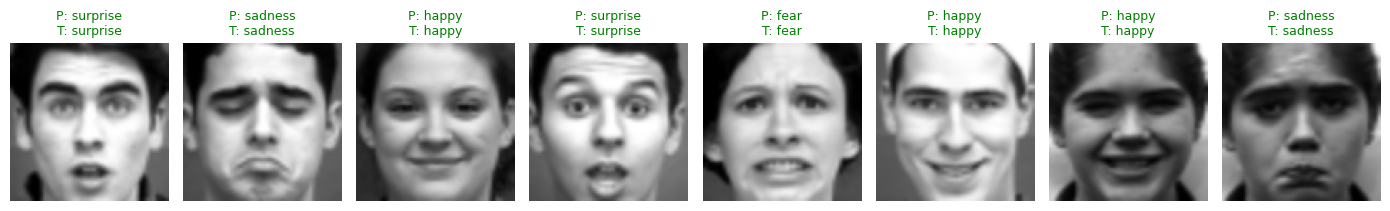

In [3]:
import os
import time
import zipfile
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.model_selection import train_test_split

start_time = time.time()
tf.keras.utils.set_random_seed(42)

# ---------------------------------------------------------
# 1. LOAD CK+ DATASET & STRATIFIED SPLIT
# ---------------------------------------------------------
extract_dir = '/content/ck_data'
zip_matches = glob.glob('/content/**/*.zip', recursive=True)
csv_matches = [c for c in glob.glob('/content/**/*.csv', recursive=True) if 'sample_data' not in c]

use_csv = len(csv_matches) > 0 and not os.path.exists(extract_dir)

if use_csv:
    print(f"Loading CK+ from CSV: {csv_matches[0]}")
    df = pd.read_csv(csv_matches[0])

    label_map = {
        0: 'Anger', 1: 'Disgust', 2: 'Fear', 3: 'Happiness',
        4: 'Sadness', 5: 'Surprise', 6: 'Neutral', 7: 'Contempt'
    }
    unique_labels = sorted(df['emotion'].unique())
    class_names = [label_map.get(int(k), str(k)) for k in unique_labels]
    remapped = {old_val: idx for idx, old_val in enumerate(unique_labels)}
    y = df['emotion'].map(remapped).values.astype(np.int32)

    first_pixels = np.fromstring(str(df['pixels'].iloc[0]), sep=' ', dtype=np.float32)
    img_size = int(np.sqrt(len(first_pixels)))
    assert img_size * img_size == len(first_pixels), "Unexpected pixel count in CSV."

    gray = np.stack([
        np.fromstring(str(p), sep=' ', dtype=np.float32).reshape(img_size, img_size)
        for p in df['pixels']
    ], axis=0)
    # Repeat grayscale to 3 channels for MobileNetV2 (96x96 keeps CPU fast)
    X_rgb = tf.image.resize(np.repeat(gray[..., None], 3, axis=-1), (96, 96)).numpy()

else:
    if not os.path.exists(extract_dir):
        assert len(zip_matches) > 0, "Please upload your CK+ .zip or .csv file to Colab Files first!"
        print(f"Extracting {zip_matches[0]}...")
        with zipfile.ZipFile(zip_matches[0], 'r') as z:
            z.extractall(extract_dir)

    best_root = extract_dir
    max_subdirs = 0
    for root, dirs, _ in os.walk(extract_dir):
        valid_subdirs = [
            d for d in dirs
            if len(glob.glob(os.path.join(root, d, '*.*'))) > 0
        ]
        if len(valid_subdirs) > max_subdirs:
            max_subdirs = len(valid_subdirs)
            best_root = root

    raw_ds = tf.keras.utils.image_dataset_from_directory(
        best_root,
        color_mode='rgb',
        image_size=(96, 96),
        batch_size=64,
        shuffle=False
    )
    class_names = raw_ds.class_names

    x_list, y_list = [], []
    for bx, by in raw_ds:
        x_list.append(bx.numpy())
        y_list.append(by.numpy())

    X_rgb = np.concatenate(x_list, axis=0).astype(np.float32)
    y = np.concatenate(y_list, axis=0).astype(np.int32)

print("Classes:", class_names)
print("Total samples:", len(X_rgb))

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_rgb, y, test_size=0.2, stratify=y, random_state=42
)

# ---------------------------------------------------------
# 2. PRE-EXTRACT FEATURES ONCE WITH FROZEN MOBILENETV2
# ---------------------------------------------------------
# Computing bottleneck features once makes training epochs nearly instant on CPU
base_model = MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights='imagenet',
    pooling='avg'
)
base_model.trainable = False

X_train_feat = base_model.predict(preprocess_input(X_train_raw.copy()), batch_size=64, verbose=0)
X_val_feat = base_model.predict(preprocess_input(X_val_raw.copy()), batch_size=64, verbose=0)

# ---------------------------------------------------------
# 3. TRAIN CLASSIFIER HEAD
# ---------------------------------------------------------
clf = models.Sequential([
    layers.Input(shape=(X_train_feat.shape[1],)),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')
])

clf.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = clf.fit(
    X_train_feat, y_train,
    validation_data=(X_val_feat, y_val),
    epochs=25,
    batch_size=32,
    verbose=1
)

_, val_acc = clf.evaluate(X_val_feat, y_val, verbose=0)
elapsed = time.time() - start_time
print(f"\nValidation Accuracy: {val_acc * 100:.2f}%")
print(f"Total Execution Time: {elapsed:.1f} seconds")

# ---------------------------------------------------------
# 4. PLOT ACCURACY & LOSS CURVES
# ---------------------------------------------------------
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('CK+ Feature Classifier Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('CK+ Feature Classifier Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. VISUALIZE SAMPLE PREDICTIONS (P = Predicted, T = True)
# ---------------------------------------------------------
n_show = min(8, len(X_val_raw))
sample_imgs = np.clip(X_val_raw[:n_show] / 255.0, 0.0, 1.0)
sample_labels = y_val[:n_show]
preds = np.argmax(clf.predict(X_val_feat[:n_show], verbose=0), axis=1)

plt.figure(figsize=(14, 4))
for i in range(n_show):
    plt.subplot(1, n_show, i + 1)
    plt.imshow(sample_imgs[i])
    matched = preds[i] == sample_labels[i]
    plt.title(
        f"P: {class_names[preds[i]]}\nT: {class_names[sample_labels[i]]}",
        color='green' if matched else 'red',
        fontsize=9
    )
    plt.axis('off')

plt.tight_layout()
plt.show()